<a href="https://colab.research.google.com/github/bsheese/387/blob/main/19_onramp/19_0_Whole_Game/19_0_2_What_Just_Happened.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Whole Game: Part 2
## What Just Happened?

---

## What This Notebook Is About

In 19_0_1 you fine-tuned a pretrained network to tell four pet breeds apart, and it got most of the test photos right. This notebook looks more closely at that model, still without opening up how it works inside:

1. Every photo becomes 512 numbers before the last layer sees it. We compute those numbers for all 800 photos.
2. We put the test results in a table and see which breeds the model gets wrong, and what it picks instead.
3. We look at the photos it gets wrong, and ask whether a person might make the same mistakes.
4. We look at how sure the model is of its answers, when it's right and when it's wrong.
5. We show it photos of breeds it was never trained on.
6. We save the model's predictions and the 512 numbers to files. All four 19_1 notebooks use them.

The notebook ends with a short history of how deep learning got here and a discussion of where the photos came from and who is missing from them.

Like 19_0_1, this notebook runs on a GPU or a CPU. Nothing in it trains a model, so a CPU is fine; the slowest cell takes a minute or two.

---

## Section 1: Rebuilding the Model

Colab didn't keep yesterday's files, so we start by rebuilding the model. The course keeps a copy of the trained last layer, made by running 19_0_1. We use that copy rather than your own, so that everyone in the class works with exactly the same model. The 19_1 notebooks and the unit 19 exam ask questions about this particular model, so it matters that the numbers you see are the same ones your classmates see.

The next cell repeats the setup from 19_0_1: it loads the libraries, downloads the photos, downloads the pretrained ResNet-18, and replaces its last layer with the course copy of our four-breed layer.

In [1]:
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import datasets, models
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Running on:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)
    return name

with zipfile.ZipFile(fetch('pets4.zip')) as z:
    z.extractall('.')
BREEDS = sorted(os.listdir('pets4/train'))   # ['Birman', 'Ragdoll', 'basset_hound', 'beagle']

weights = models.ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
model = models.resnet18(weights=weights)
model.fc = nn.Linear(512, len(BREEDS))
model.fc.load_state_dict(torch.load(fetch('pets4_head.pt'), map_location='cpu'))
model.eval()
model = model.to(device)
print('Model ready. Breeds:', BREEDS)

Running on: cpu


Model ready. Breeds: ['Birman', 'Ragdoll', 'basset_hound', 'beagle']


---

## Section 2: Every Photo as 512 Numbers

In 19_0_1 we said that the last layer receives 512 numbers that the rest of the network computes from the photo. Those numbers are called the photo's **features**. The rest of the network (everything except the last layer) is a machine for turning a photo into features, and the last layer turns the features into four scores, one per breed.

We can see the features by temporarily taking the last layer out. `nn.Identity()` is a layer that passes its input through unchanged, so with it in place of the last layer, the model outputs the 512 features instead of the four scores. The next cell does this for all 800 photos (train, validation and test) and puts the results in one array with one row per photo. It is the slowest cell in the notebook.

In [2]:
head = model.fc                  # set the trained last layer aside
model.fc = nn.Identity()         # now the model outputs the 512 features

files, splits, labels, feature_batches = [], [], [], []
for split in ['train', 'val', 'test']:
    data = datasets.ImageFolder(f'pets4/{split}', transform=preprocess)
    with torch.no_grad():
        for x, y in torch.utils.data.DataLoader(data, batch_size=64):
            feature_batches.append(model(x.to(device)).cpu())
    files += [os.path.basename(path) for path, _ in data.samples]
    splits += [split] * len(data)
    labels += [BREEDS[label] for label in data.targets]

model.fc = head                  # put the last layer back
features = torch.cat(feature_batches)
print('features has shape', tuple(features.shape))

features has shape (800, 512)


The shape `(800, 512)` means 800 rows (one per photo) and 512 columns (one per feature). Here are the first ten features of the first photo:

In [3]:
print(files[0], labels[0])
print(features[0, :10].numpy().round(2))

Birman_106.jpg Birman
[0.3  1.   1.78 0.14 0.2  0.38 0.3  0.2  1.45 2.  ]


The individual numbers don't mean anything we can name. No column is "ear length" or "fur color". The network learned on ImageNet to compute whatever numbers helped it tell 1,000 categories apart, and it turns out that those same numbers are also useful for telling our four breeds apart. That is the reason fine-tuning worked so well with so few photos. (22_1 looks at what some of these numbers respond to.)

Since the last layer only ever sees these 512 numbers, we can get the model's scores by running just the last layer on the features. That is much faster than running the whole network again. The scores are turned into probabilities that add up to 1 with a function called **softmax** (19_1_4 shows how it works), and the predicted breed is the one with the highest probability.

In [4]:
with torch.no_grad():
    scores = head(features.to(device)).cpu()     # 4 scores per photo
probs = scores.softmax(dim=1)                    # 4 probabilities per photo, adding up to 1
predicted = [BREEDS[i] for i in probs.argmax(dim=1)]

print('scores for the first photo:       ', scores[0].numpy().round(2))
print('probabilities for the first photo:', probs[0].numpy().round(3), ' sum =', round(probs[0].sum().item(), 3))
print('predicted breed:', predicted[0], '  true breed:', labels[0])

scores for the first photo:        [ 2.44 -0.87 -4.38 -1.66]
probabilities for the first photo: [0.949 0.035 0.001 0.016]  sum = 1.0
predicted breed: Birman   true breed: Birman


As a check, running the first photo through the whole model, the way the `predict` function did in 19_0_1, gives the same probabilities (up to tiny rounding differences):

In [5]:
x = preprocess(Image.open(f'pets4/train/{labels[0]}/{files[0]}').convert('RGB')).unsqueeze(0).to(device)
with torch.no_grad():
    print(model(x).softmax(dim=1)[0].cpu().numpy().round(3))

[0.949 0.035 0.001 0.016]


---

## Section 3: The Test Results in a Table

From here on we only look at the 200 test photos, which the model never learned from. A **pandas DataFrame** is a table with named columns. You don't need to know pandas for this course; the code below only builds the table and counts things in it.

Each row is one test photo: its true breed, the model's prediction, and the probability the model gave to its prediction (how sure it was).

In [6]:
results = pd.DataFrame({'file': files, 'split': splits, 'breed': labels, 'predicted': predicted})
for i, breed in enumerate(BREEDS):
    results[f'score_{breed}'] = scores[:, i].numpy()
for i, breed in enumerate(BREEDS):
    results[f'prob_{breed}'] = probs[:, i].numpy()
results['confidence'] = probs.max(dim=1).values.numpy()
results['correct'] = results['breed'] == results['predicted']

test = results[results['split'] == 'test']
test[['file', 'breed', 'predicted', 'confidence', 'correct']].head(8)

,file,breed,predicted,confidence,correct
600,Birman_1.jpg,Birman,Birman,0.822686,True
601,Birman_10.jpg,Birman,Birman,0.889735,True
602,Birman_103.jpg,Birman,Birman,0.839673,True
603,Birman_108.jpg,Birman,Birman,0.866312,True
604,Birman_110.jpg,Birman,Birman,0.959777,True
605,Birman_118.jpg,Birman,Birman,0.981093,True
606,Birman_119.jpg,Birman,Birman,0.898642,True
607,Birman_120.jpg,Birman,Ragdoll,0.612892,False


In [7]:
print(f"Test accuracy: {test['correct'].mean():.3f}  ({test['correct'].sum()} of {len(test)} right)")
print()
print('Right answers out of 50, by true breed:')
print(test.groupby('breed')['correct'].sum())

Test accuracy: 0.900  (180 of 200 right)

Right answers out of 50, by true breed:
breed
Birman          46
Ragdoll         38
basset_hound    46
beagle          50
Name: correct, dtype: int64


The overall accuracy hides a difference between the breeds. The next table counts, for each true breed (rows), how many of its test photos were given each predicted breed (columns). The numbers on the diagonal, from top left to bottom right, are the right answers, and everything else is a mistake.

In [8]:
pd.crosstab(test['breed'], test['predicted'], rownames=['true breed'], colnames=['predicted breed'])

predicted breed,Birman,Ragdoll,basset_hound,beagle
true breed,,,,
Birman,46,4,0,0
Ragdoll,12,38,0,0
basset_hound,0,0,46,4
beagle,0,0,0,50


A table like this is called a **confusion matrix**, and 19_1_2 spends a whole class on it. For now, read the off-diagonal numbers and notice where they are. The mistakes stay inside the two look-alike pairs: Birmans and Ragdolls get confused with each other, and so do basset hounds and beagles, but the model doesn't call a cat a dog. Most of the mistakes are Ragdolls that the model calls Birmans.

---

## Section 4: Looking at the Mistakes

Numbers only tell you so much. The next cell shows every test photo the model got wrong, with the true breed, the predicted breed and how sure the model was.

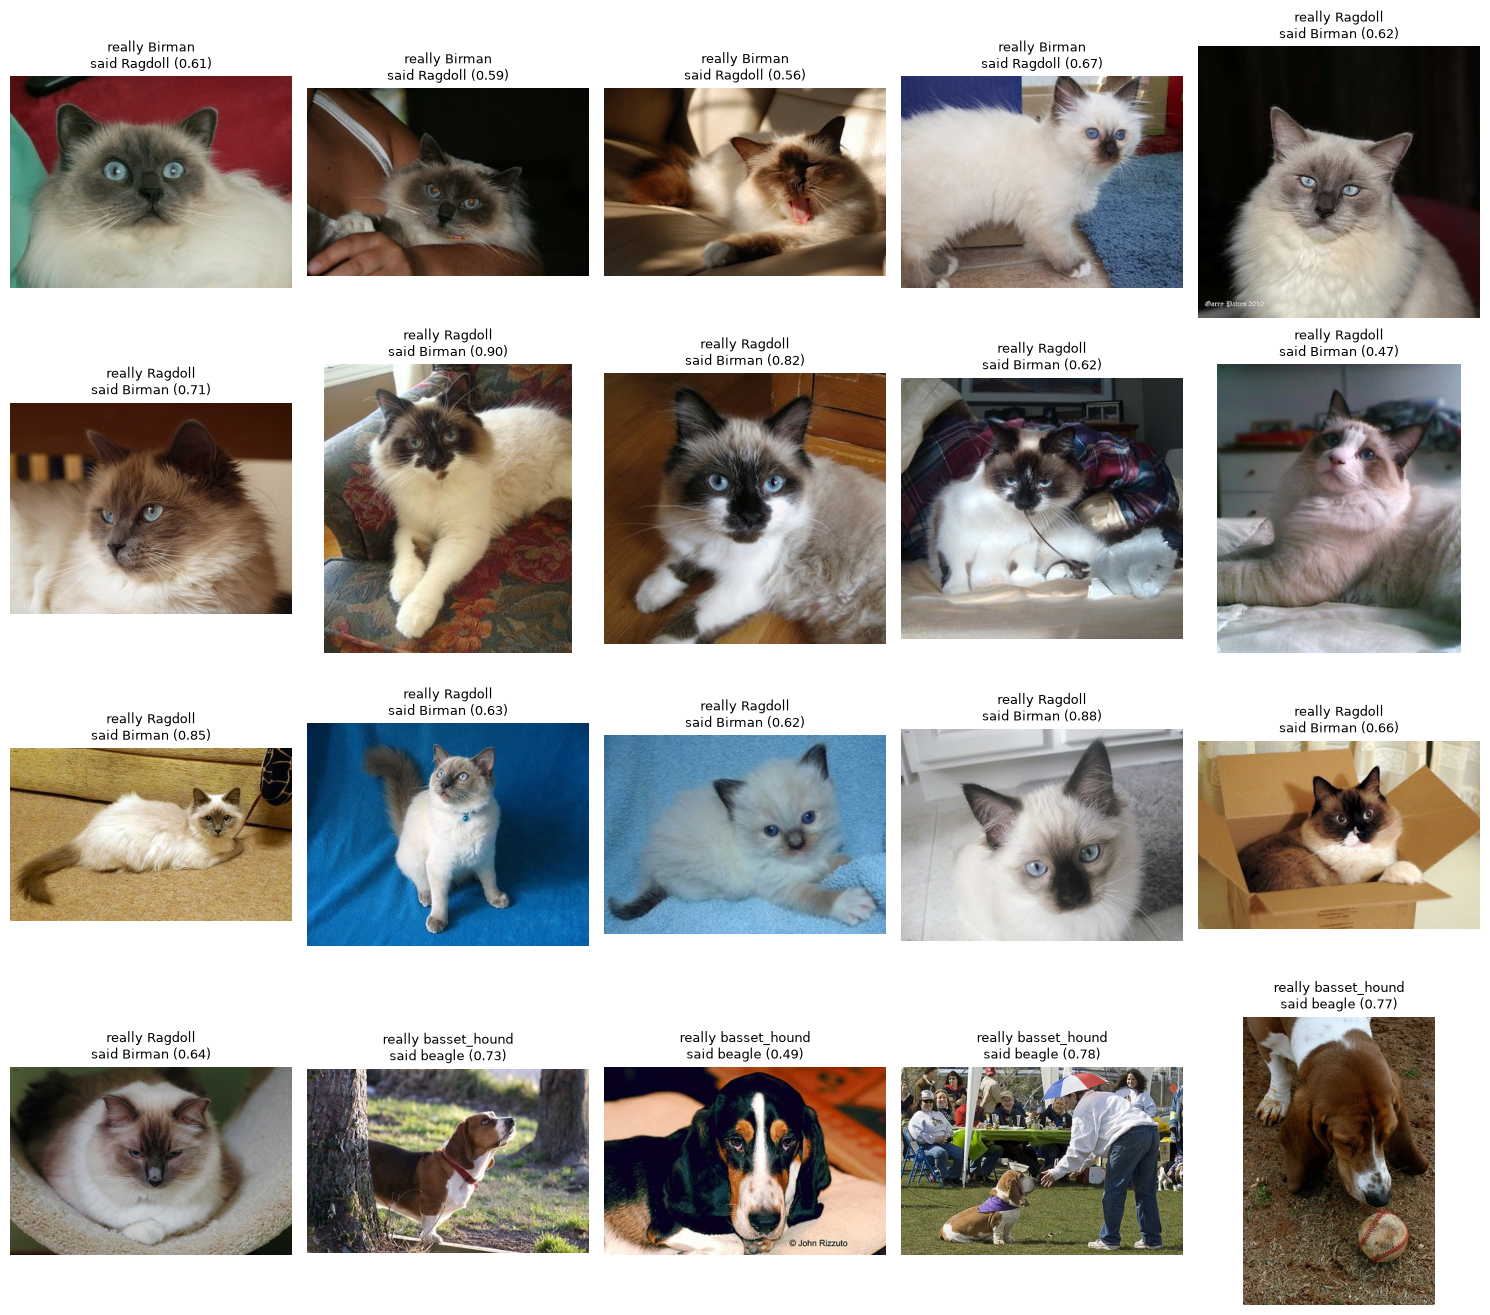

In [9]:
wrong = test[~test['correct']]
n_cols = 5
n_rows = (len(wrong) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.3 * n_rows))
for ax in axes.flat:
    ax.axis('off')
for ax, (_, row) in zip(axes.flat, wrong.iterrows()):
    ax.imshow(Image.open(f"pets4/test/{row['breed']}/{row['file']}"))
    ax.set_title(f"really {row['breed']}\nsaid {row['predicted']} ({row['confidence']:.2f})", fontsize=9)
plt.tight_layout()
plt.show()

Questions to discuss with your partner:

- Look at the Ragdolls that were called Birmans. Do they have white paws? If you could only see the photo, would you have gotten them right?
- Are there photos where the animal is small, partly hidden, or in an unusual pose? How many of the mistakes look like that?
- Is there any mistake you would call clearly wrong, one that a person would never make?

---

## Section 5: How Sure Is the Model?

For every photo the model gives a probability to each breed, and the probability of the breed it picks is its **confidence**. A useful model should be less sure of itself when it's wrong than when it's right. The next plot compares the confidence of the right answers with the confidence of the wrong ones.

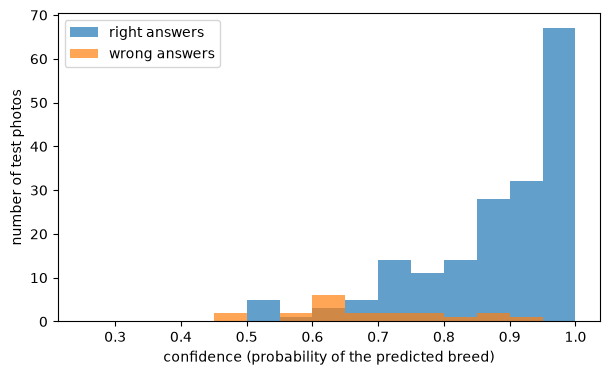

Average confidence when right: 0.878
Average confidence when wrong: 0.683
Wrong answers with confidence above 0.8: 4


In [10]:
bins = np.linspace(0.25, 1, 16)
plt.figure(figsize=(7, 4))
plt.hist(test.loc[test['correct'], 'confidence'], bins=bins, alpha=0.7, label='right answers')
plt.hist(test.loc[~test['correct'], 'confidence'], bins=bins, alpha=0.7, label='wrong answers')
plt.xlabel('confidence (probability of the predicted breed)')
plt.ylabel('number of test photos')
plt.legend()
plt.show()

print('Average confidence when right:', round(test.loc[test['correct'], 'confidence'].mean(), 3))
print('Average confidence when wrong:', round(test.loc[~test['correct'], 'confidence'].mean(), 3))
print('Wrong answers with confidence above 0.8:', ((~test['correct']) & (test['confidence'] > 0.8)).sum())

Most right answers come with a confidence above 0.8, and the largest group is between 0.95 and 1. The wrong answers are more spread out, and on average the model is less sure of them, which is what we'd hope for. But a few wrong answers still come with a confidence above 0.8, so a high probability does not guarantee a right answer.

The confidence can't go below 0.25: with four breeds, the highest of four probabilities that add up to 1 is at least one quarter.

---

## Section 6: Photos Outside the Four Breeds

The photo archive also has ten photos of breeds the model has never been trained on: Siamese and Persian cats, and pug, samoyed and keeshond dogs. What does the model say about them?

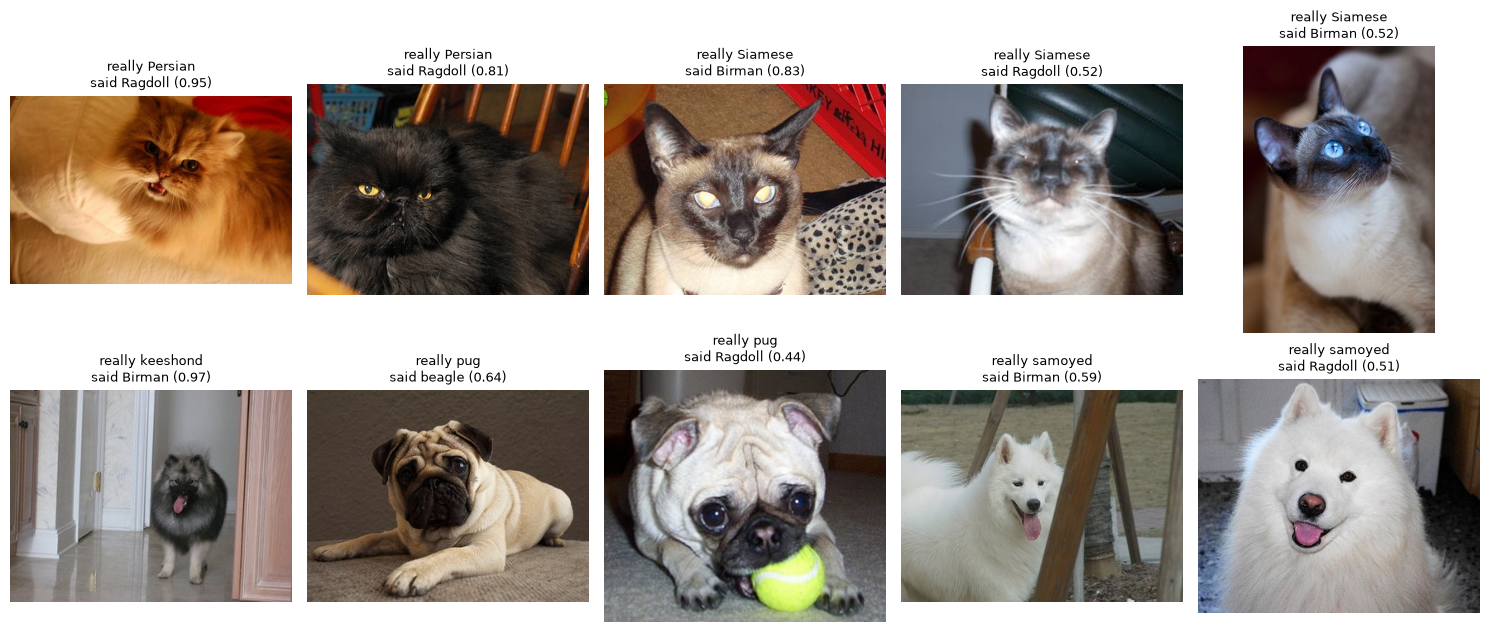

In [11]:
other_files = sorted(os.listdir('pets4/other'))
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, name in zip(axes.flat, other_files):
    img = Image.open(f'pets4/other/{name}').convert('RGB')
    with torch.no_grad():
        p = model(preprocess(img).unsqueeze(0).to(device)).softmax(dim=1)[0].cpu()
    true_breed = name.rsplit('_', 1)[0]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f'really {true_breed}\nsaid {BREEDS[p.argmax()]} ({p.max():.2f})', fontsize=9)
plt.tight_layout()
plt.show()

Every photo gets one of the four breeds, because those are the only answers the model has. It has no way to say "none of these" or "I don't know".

Look at the confidence numbers too. For some of these photos the model is very sure of an answer that can't be right. It calls the orange Persian cat a Ragdoll with a probability of 0.95, and it calls the keeshond, which is a dog, a Birman with a probability of 0.97. On the test photos the model never called a dog a cat, but here several of the unfamiliar dogs get cat breeds. What the model learned holds up on photos like the ones it was trained on, and we have no guarantee about anything else.

This matters well beyond pet photos. A model only learns from the kinds of examples it was shown, but once people use it, it will be given whatever they give it, and its answers look just as confident either way.

---

## Section 7: Saving the Model's Outputs for 19_1

The 19_1 notebooks teach how to evaluate a model, and they use this model's outputs to do it, so that nobody has to wait for the network to run again. The next cell saves two files:

- `pets4_predictions.csv`: one row for each of the 800 photos, with its split, true breed, predicted breed, the four scores and the four probabilities.
- `pets4_features.npz`: the 512 features of every photo (`features`), with the file name (`filename`), split (`split`) and true breed (`breed`) of each row.

The course keeps copies of both files, made by running this notebook, and the 19_1 notebooks download those copies. So you don't need to keep the files you make here, and the numbers in 19_1 will match the ones in this notebook.

In [12]:
results.drop(columns=['confidence', 'correct']).to_csv('pets4_predictions.csv', index=False)
np.savez_compressed('pets4_features.npz', features=features.numpy(),
                    filename=np.array(files), split=np.array(splits), breed=np.array(labels))
print('Saved pets4_predictions.csv and pets4_features.npz')

Saved pets4_predictions.csv and pets4_features.npz


---

## Section 8: How We Got Here

The model you trained in 19_0_1 sits on top of about 70 years of work. Here are the main steps, with where each one comes up in this course.

| Year | What happened | In this course |
|---|---|---|
| 1958 | Frank Rosenblatt's **perceptron**: a single artificial neuron that learns its weights from examples | 19_1_3, one neuron |
| 1969 | Minsky and Papert show that a single neuron can't learn some simple patterns, such as XOR; interest in neural networks drops for years | 19_1_4 and 20_1, XOR |
| 1986 | Rumelhart, Hinton and Williams popularize **backpropagation**, a way to train networks with hidden layers | unit 20 |
| 1998 | LeCun's **LeNet**, a convolutional network that reads handwritten digits on bank checks | 22_0, convolution |
| 2009 | Fei-Fei Li's team releases **ImageNet**, millions of web photos labeled by crowd workers | the data behind ResNet-18 |
| 2012 | **AlexNet**, a convolutional network trained on GPUs, wins the ImageNet competition by a wide margin; this is usually taken as the start of the deep learning boom | 22_0 |
| 2015 | **ResNet**, the family our model comes from, wins the ImageNet competition with networks over 100 layers deep | 19_0, 22_1 |
| 2017 | The **transformer**, built on attention, is published for machine translation | 23_1, attention |
| 2018 to now | Large pretrained language models (BERT, GPT and their successors) and image generators built on diffusion | 23_2, 23_3, 22_2 |

The ideas behind neural networks are old. What changed around 2012 was mostly scale: much larger labeled datasets, GPUs that made training on them practical, and researchers sharing their pretrained models, so that anyone can start from one, the way we did in 19_0_1.

---

## Section 9: Where the Photos Came From, and Who Is Missing

Every model learns from some particular set of examples, and it's worth asking where they came from. Discuss these questions with your partner.

**The pet photos.** The Oxford-IIIT Pet photos were collected from the web, from photo-sharing and pet websites, and then labeled with a breed.
- Every animal in the dataset is a purebred of one of 37 breeds. Most pet cats and dogs are mixed breeds. What would this model say about them, and how would anyone using it know it was wrong?
- The photos are ones that people chose to take and post online. What kinds of animals, settings or photos would that leave out?

**ImageNet.** Our model learned most of what it knows from ImageNet, before it ever saw a pet. ImageNet's photos were found with web search engines and labeled by paid crowd workers, mostly through Amazon Mechanical Turk.
- Whose photos are on the web, and whose aren't? Which parts of the world, and which kinds of everyday objects, would be underrepresented?
- ImageNet also has categories for people. In 2019, after researchers and artists showed that many of the labels on photos of people were offensive or meaningless, the ImageNet team removed a large part of those categories. Who decides what the labels in a dataset should be, and who checks them?

**Our four breeds.** We chose breeds that come in look-alike pairs to make the problem interesting. A different choice of breeds would give a different accuracy. When you read that a model is "92% accurate", what would you want to know about how the test examples were chosen?

---

## Summary

- The pretrained network turns every photo into 512 **features**, and the last layer turns the features into four scores. **Softmax** turns the scores into probabilities that add up to 1.
- On the test photos, the model's mistakes stay inside the two look-alike pairs. It confuses Ragdolls with Birmans most often, and it never calls a cat a dog.
- A table of true breeds against predicted breeds, called a **confusion matrix**, shows where the mistakes are. 19_1_2 covers it properly.
- The model is usually less confident when it's wrong, but some wrong answers still come with high confidence.
- Given a breed it was never trained on, the model still answers with one of its four breeds, because it has no "none of these" answer. Some of those answers are very confident, and some unfamiliar dogs even get cat breeds.
- The model's predictions and every photo's features are saved to files that 19_1 uses.

**Next:** 19_1_1 asks whether this model is actually any good, starting from the simplest possible comparison: a "model" that always predicts the same breed.